# AA 279B - Homework 3 Problem 3

## Imports

In [35]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
from lamberthub import vallado2013
import plotly.graph_objects as go
from tqdm import tqdm

## Constants

In [37]:
RAD_TO_SIDEREAL_HOUR = 24.0/np.pi/2.0
MIN_TO_SEC = 60
HOUR_TO_SEC = 60 * MIN_TO_SEC
DAY_TO_SEC = 24 * HOUR_TO_SEC

M_TO_KM = 1.0/1000

DEG_TO_RAD = np.pi/180.0
RAD_TO_DEG = 1/DEG_TO_RAD

# km3/m2
MU_EARTH = 398600.4418

# km
R_EARTH = 6378.137

# rad/s
W_EARTH = 0.0000729211585530

MIN_TO_SEC = 60

In [38]:
# For sidereal 

# 00:00 Jan 1 2014, UTC
t_utc_2014 = 1388534400 
theta_utc_2014 = 6.7045617 / RAD_TO_SIDEREAL_HOUR

# Launcher data
launch_lon = -122.081944 * DEG_TO_RAD
launch_lat = 37.389444 * DEG_TO_RAD
launch_alt = 11 * M_TO_KM

# Dove 3 Orbital Elements
dove_epoch_day_num = 21.68857885
dove_epoch_utc = (dove_epoch_day_num - 1) * DAY_TO_SEC + t_utc_2014
i_dove = 97.7791 * DEG_TO_RAD
raan_dove = 95.3093 * DEG_TO_RAD
e_dove = 0.0155616
aop_dove = 357.8679 * DEG_TO_RAD
M_dove = 2.1812 * DEG_TO_RAD
n_dove = 14.56715041 / DAY_TO_SEC * 2 * np.pi # rev/day --> rad/s

a_dove = (MU_EARTH / n_dove/n_dove)**((1/3)) # Calc

# Sim start
# 0100h on 23 January 2014 UTC
sim_start_utc = 1390438800

## Part a

In [39]:
def calc_theta_g(t_utc, omega = W_EARTH, theta_ref = theta_utc_2014, t_ref = t_utc_2014):
    """Simple rotation from Greenwich

    Parameters
    ----------
    t_utc : float
        seconds
    omega : float, optional
        default `W_EARTH`
    theta_ref : float, optional
        default `theta_utc_2014`
    t_ref : float, optional
        unix epoch of Jan 1, 2024, default `time_utc_2014`
        
    Returns
    ------
    theta_g : float
    """
    return theta_ref + omega * (t_utc - t_ref)

## Part b

In [40]:
def kepler(M, e):
    """Vallado 4e eq. 2-4 p. 45 (pdf p. 72)"""
    E = fsolve(lambda E: E - e*np.sin(E) - M, M)[0]
    return E

def dcm_x(theta):
    """theta: angle of frame 2 wrt frame 1"""
    return np.array([
        [1, 0, 0],
        [0, np.cos(theta), np.sin(theta)],
        [0, -np.sin(theta), np.cos(theta)]
    ])

def dcm_y(theta):
    """theta: angle of frame 2 wrt frame 1"""
    return np.array([
        [np.cos(theta), 0, -np.sin(theta)],
        [0, 1, 0],
        [np.sin(theta), 0, np.cos(theta)]
    ])
    
def dcm_z(theta):
    """theta: angle of frame 2 wrt frame 1"""
    return np.array([
        [np.cos(theta), np.sin(theta), 0],
        [-np.sin(theta), np.cos(theta), 0],
        [0, 0, 1]
    ])
    

def rv_from_coe(a, e, i, raan, aop, M, mu = MU_EARTH) -> tuple[np.ndarray, np.ndarray]:
    """Vallado 4e Algorithm 10 p. 118 (pdf p. 145)"""

    # semiparameter - Vallado 4e p. 96 (pdf p. 123)
    p = a*(1 - e*e)
    
    E = kepler(M,e)
    
    # true anomaly - Vallado 4e. eq. 2-10 p. 47 (pdf p. 74)
    nu = 2 * np.arctan2(
    np.sqrt(1 + e) * np.sin(E / 2),
    np.sqrt(1 - e) * np.cos(E / 2)
)
    r_pqw = np.array([
        p*np.cos(nu),
        p*np.sin(nu),
        0
    ]) / (1 + e*np.cos(nu))
    
    v_pqw = np.array([
        -np.sin(nu),
        e + np.cos(nu),
        0
    ]) * np.sqrt(mu/p)
    
    dcm_ijk_wrt_pqw = dcm_z(-raan) @ dcm_x(-i) @ dcm_z(-aop)
    r_ijk = dcm_ijk_wrt_pqw @ r_pqw
    v_ijk = dcm_ijk_wrt_pqw @ v_pqw

    return r_ijk, v_ijk
    

# Vallado 4e example 2-6 p. 119 (pdf p. 146)
assert np.allclose(
    np.array(rv_from_coe(
        a = 36126.6428348052,
        e = 0.83285,
        i = 87.87 * DEG_TO_RAD,
        raan = 227.89 * DEG_TO_RAD,
        aop = 53.38 * DEG_TO_RAD,
        M = 7.60494 * DEG_TO_RAD)),
    np.array([
        [6525.344, 6861.535, 6449.125],
        [4.902276, 5.533124, -1.975709]
    ]) 
)

## Calculation

In [41]:
dt_launch = 1 * MIN_TO_SEC # seconds
dt_tof = 1 * MIN_TO_SEC # seconds
# MAX_LAUNCH_DELAY = 24 * HOUR_TO_SEC
# MAX_TOF = 120 * MIN_TO_SEC

MIN_LAUNCH_DELAY = 0
MAX_LAUNCH_DELAY = 6 * HOUR_TO_SEC
MIN_TOF = 0
MAX_TOF = 2 * HOUR_TO_SEC

t_arr_launch = np.arange(MIN_LAUNCH_DELAY, MAX_LAUNCH_DELAY + dt_launch, dt_launch)
t_arr_tofs = np.arange(MIN_TOF, MAX_TOF + dt_tof, dt_tof)


N_LAUNCHES = len(t_arr_launch)
N_TOFS = len(t_arr_tofs)

print(f"Total launch delays: {N_LAUNCHES}")
print(f"Total tof: {N_TOFS}")

Total launch delays: 361
Total tof: 121


### Time grid / search space

In [42]:
launch_grid, tof_grid = np.meshgrid(
    t_arr_launch,
    t_arr_tofs,
    indexing="ij"
)

# dimensions of [x_dim, y_dim]
intercept_grid = launch_grid + tof_grid
print(intercept_grid.shape)

# From beginning of ephemeris time
t_total_utc = np.unique(np.concatenate(
        (np.array(sorted(intercept_grid.ravel())),t_arr_launch)
    )) + sim_start_utc # all places to evaluate

time_pairs = np.stack([
    launch_grid.ravel(),
    intercept_grid.ravel()
], axis=1)

(361, 121)


In [81]:

fig = go.Figure()

# plotly expects [y_dim, x_dim] so z.T
fig.add_trace(go.Heatmap(
    x=t_arr_launch,
    y=t_arr_tofs,
    z=intercept_grid.T,
    colorscale="Viridis",
    colorbar=dict(title="Arrival time [s]"),
    opacity=0.8,
))

fig.add_trace(go.Contour(
    x=t_arr_launch,
    y=t_arr_tofs,
    z=intercept_grid.T,
    showscale=False,
    line=dict(width=2, color="black"),
    contours=dict(
        coloring="lines",
        showlabels=True,
        start=0,
        end=np.max(intercept_grid),
        size=2500,
        labelfont=dict(size=10, color="black")
    )
))

# fig.add_trace(go.Scatter(
#     x=launch_grid.ravel(),
#     y=tof_grid.ravel(),
#     mode="markers",
#     marker=dict(
#         size=4,
#         color="black",
#         opacity=0.7
#     ),
#     name="Grid points"
# ))

fig.update_layout(
    xaxis_title="Launch time [s]",
    yaxis_title="TOF [s]",
    title="Search Space",
    width=2000,
    height=500
)

fig.update_xaxes(
    range=[np.min(t_arr_launch), np.max(t_arr_launch)],
    constrain="domain"
)

fig.update_yaxes(
    range=[np.min(t_arr_tofs), np.max(t_arr_tofs)],
    constrain="domain"
)

fig.show()

In [44]:
def plot_3d(
    t_arrs,
    traces,
    labels="Orbit",
    title="3D Orbits",
    r_earth=R_EARTH,
    t_max=None
):

    fig = go.Figure()

    # Earth
    u_ = np.linspace(0, 2*np.pi, 80)
    v_ = np.linspace(0, np.pi, 40)

    x_earth = r_earth * np.outer(np.cos(u_), np.sin(v_))
    y_earth = r_earth * np.outer(np.sin(u_), np.sin(v_))
    z_earth = r_earth * np.outer(np.ones_like(u_), np.cos(v_))

    fig.add_trace(go.Surface(
        x=x_earth,
        y=y_earth,
        z=z_earth,
        name="Earth",
        showscale=False,
        opacity=0.7,
        colorscale=[[0, "royalblue"], [1, "royalblue"]]
    ))

    # Allow a single (N,3) trajectory
    if isinstance(traces, np.ndarray) and traces.ndim == 2:
        traces = [traces]

    # One time array shared by all trajectories
    if isinstance(t_arrs, np.ndarray) and t_arrs.ndim == 1:
        t_arrs = [t_arrs] * len(traces)

    if isinstance(labels, str):
        labels = [labels] * len(traces)

    for t_arr, trace, label in zip(t_arrs, traces, labels):
        t_arr = np.asarray(t_arr)
        trace = np.asarray(trace)

        if trace.ndim != 2 or trace.shape[1] != 3:
            raise ValueError(
                f"{label}: trace must have shape (N, 3), got {trace.shape}"
            )

        if len(t_arr) != len(trace):
            raise ValueError(
                f"{label}: len(t_arr)={len(t_arr)} != len(trace)={len(trace)}"
            )

        # Clip to requested maximum time
        if t_max is not None:
            mask = t_arr <= t_max
            t_arr = t_arr[mask]
            trace = trace[mask]

        if len(t_arr) < 2:
            continue

        cs = CubicSpline(t_arr, trace, axis=0)

        t_fine = np.linspace(t_arr[0], t_arr[-1], 1000)
        r_fine = cs(t_fine)

        fig.add_trace(go.Scatter3d(
            x=r_fine[:, 0],
            y=r_fine[:, 1],
            z=r_fine[:, 2],
            mode="lines",
            name=f"{label} Trajectory",
            line=dict(width=5)
        ))

        fig.add_trace(go.Scatter3d(
            x=[r_fine[-1, 0]],
            y=[r_fine[-1, 1]],
            z=[r_fine[-1, 2]],
            mode="markers",
            name=f"{label} Final position",
            marker=dict(size=6)
        ))

    fig.update_layout(
        title=title,
        scene=dict(
            xaxis_title="x [km]",
            yaxis_title="y [km]",
            zaxis_title="z [km]",
            aspectmode="data"
        ),
        template="plotly_white",
        legend=dict(x=0.02, y=0.98),
        height=900
    )

    fig.show()

### Launch positions

In [45]:
"""
Inputs:
- Time 
- Lat/lon

"""

def calc_ecef_from_lat_lon_alt(lat, lon, alt_km = 0, deg = False, r_body_km = R_EARTH):
    if deg:
        lat *= DEG_TO_RAD
        lon *= DEG_TO_RAD
        
    rho = r_body_km + alt_km
    
    r_ecef = np.array([
        rho * np.cos(lat) * np.cos(lon),
        rho * np.cos(lat) * np.sin(lon),
        rho * np.sin(lat)
    ])
    v_ecef = np.cross([0,0,W_EARTH], r_ecef)
    
    return r_ecef, v_ecef

def calc_eci_from_ecef(r_ecef, v_ecef, t_utc):
    """Somewhat simplified version of itrf-gcrs in Vallado 4e Section 3.7 pp. 203-"""
    # Earth rotation angle
    theta_ecef_wrt_eci = calc_theta_g(t_utc)
    
    dcm_eci_wrt_ecef = dcm_z(theta_ecef_wrt_eci).T
    
    r_eci = dcm_eci_wrt_ecef @ r_ecef
    v_eci = dcm_eci_wrt_ecef @ v_ecef
    
    return r_eci, v_eci

In [46]:
## Actual calculation

def launch_eci(t_arr_utc, lat, lon, alt):
    launch_r_ecef, launch_v_ecef = calc_ecef_from_lat_lon_alt(lat, lon, alt)
    
    launch_arr_eci = np.array([calc_eci_from_ecef(launch_r_ecef, launch_v_ecef, t) for t in t_arr_utc])
    launch_r_eci = launch_arr_eci[:,0,:]
    launch_v_eci = launch_arr_eci[:,1,:]
    return launch_r_eci, launch_v_eci

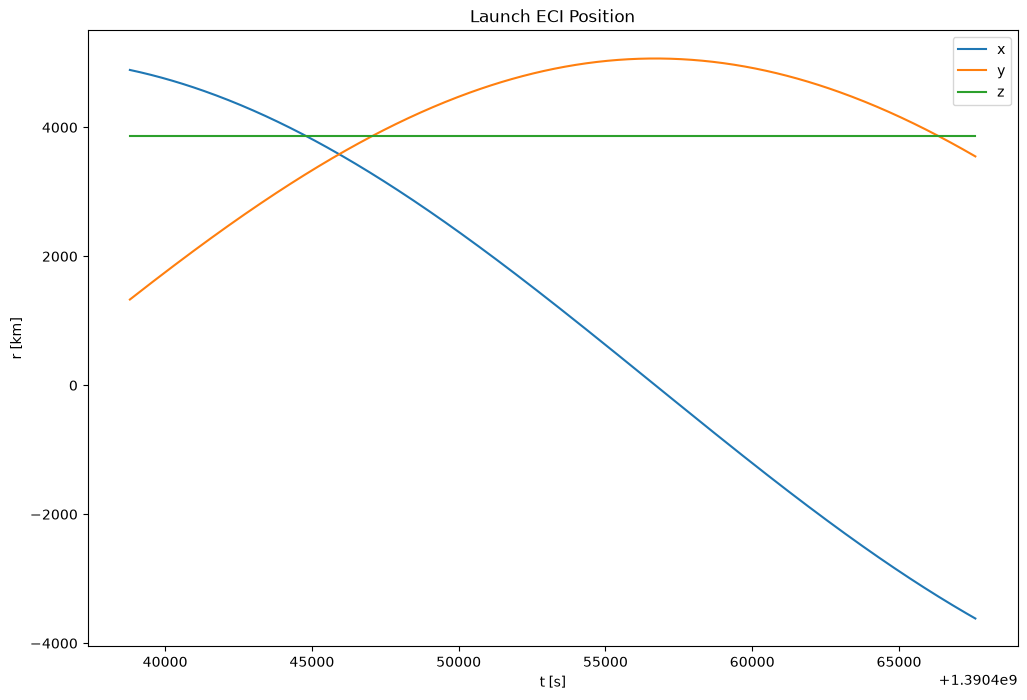

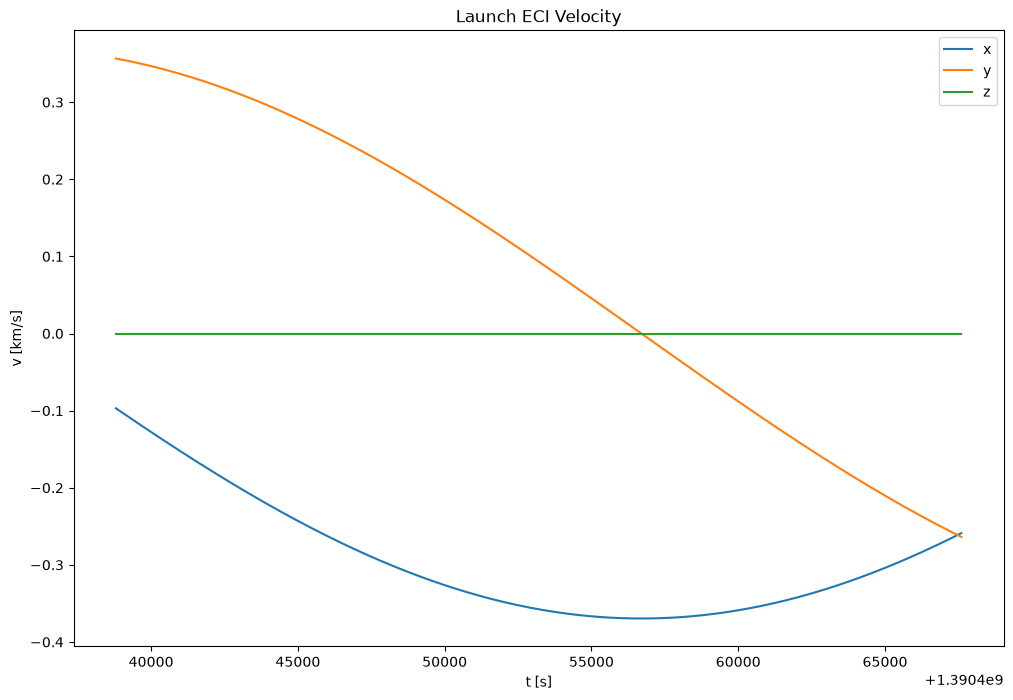

In [47]:
launch_r_eci, launch_v_eci = launch_eci(t_total_utc, launch_lat, launch_lon, launch_alt)

plt.figure(figsize=(12,8))
plt.title("Launch ECI Position")
plt.xlabel("t [s]")
plt.ylabel("r [km]")
plt.plot(t_total_utc, launch_r_eci[:,0], label = "x")
plt.plot(t_total_utc, launch_r_eci[:,1], label = "y")
plt.plot(t_total_utc, launch_r_eci[:,2], label = "z")
plt.legend()
plt.show()

plt.figure(figsize=(12,8))
plt.title("Launch ECI Velocity")
plt.xlabel("t [s]")
plt.ylabel("v [km/s]")
plt.plot(t_total_utc, launch_v_eci[:,0], label = "x")
plt.plot(t_total_utc, launch_v_eci[:,1], label = "y")
plt.plot(t_total_utc, launch_v_eci[:,2], label = "z")
plt.legend()
plt.show()

In [48]:
plot_3d(t_total_utc, launch_r_eci, "Launcher", title="3D Launch Site Position")

### Sat positions

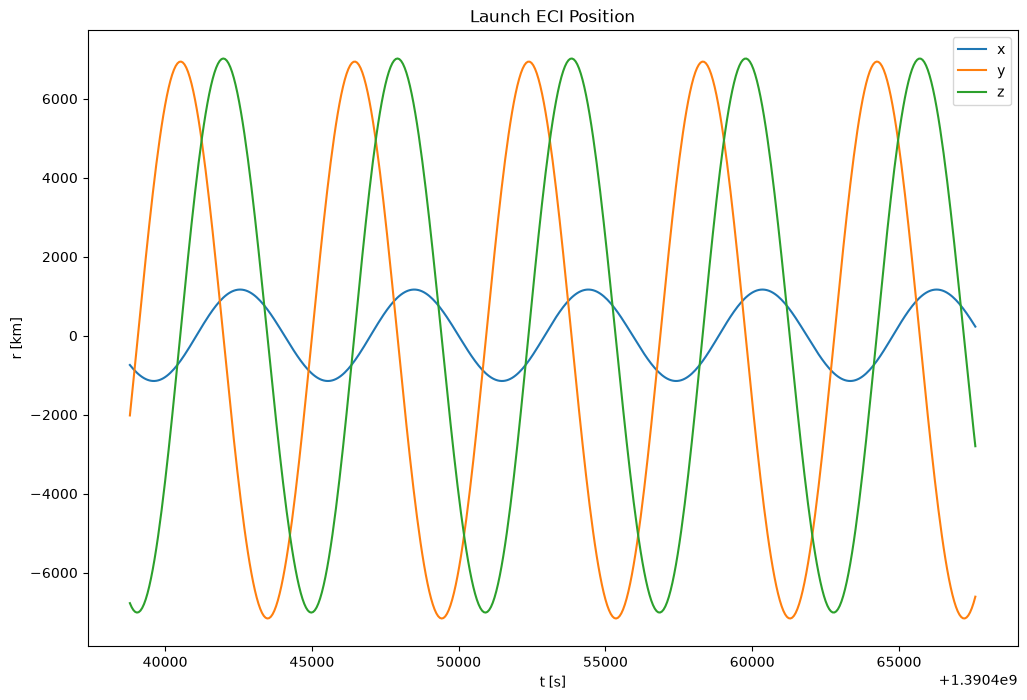

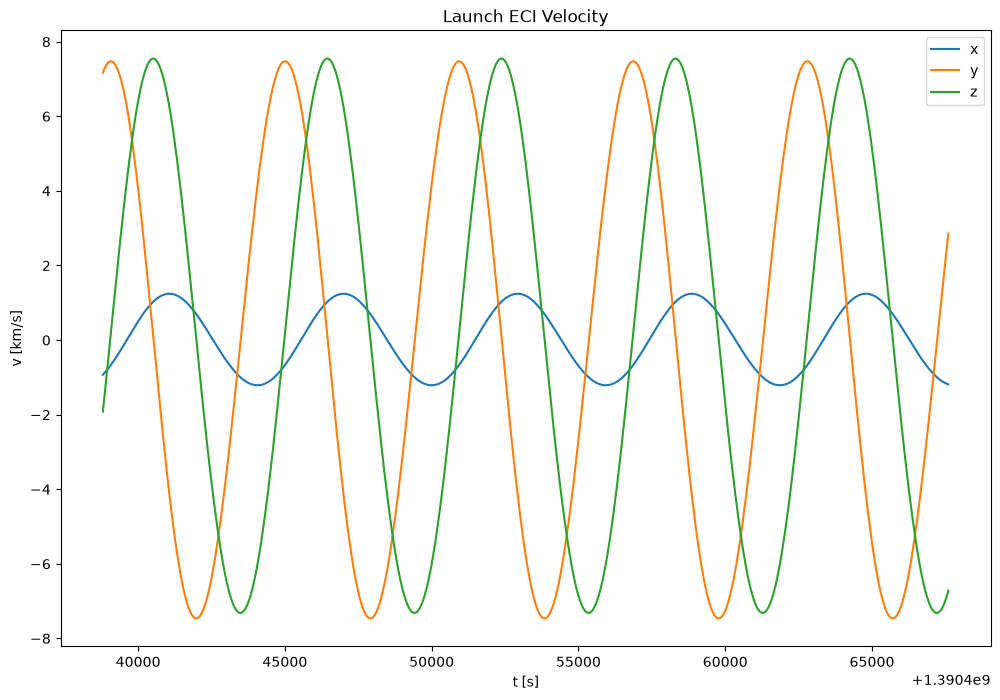

In [49]:
## Sat functions
def dove3_rv_eci(t_arr, t0 = dove_epoch_utc) -> np.ndarray | tuple[np.ndarray, np.ndarray]:
    # M_new = (M_dove + n_dove*(t_arr - t0))
    M_new = np.mod(
        M_dove + n_dove*(t_arr - t0), 2*np.pi
    )
    rv = np.array([rv_from_coe(a_dove,e_dove,i_dove,raan_dove,aop_dove,M) for M in M_new])
    r = rv[:,0,:]
    v = rv[:,1,:]
    return r,v

dove3_r_eci, dove3_v_eci = dove3_rv_eci(t_total_utc)

plt.figure(figsize=(12,8))
plt.title("Launch ECI Position")
plt.xlabel("t [s]")
plt.ylabel("r [km]")
plt.plot(t_total_utc, dove3_r_eci[:,0], label = "x")
plt.plot(t_total_utc, dove3_r_eci[:,1], label = "y")
plt.plot(t_total_utc, dove3_r_eci[:,2], label = "z")
plt.legend()
plt.show()

plt.figure(figsize=(12,8))
plt.title("Launch ECI Velocity")
plt.xlabel("t [s]")
plt.ylabel("v [km/s]")
plt.plot(t_total_utc, dove3_v_eci[:,0], label = "x")
plt.plot(t_total_utc, dove3_v_eci[:,1], label = "y")
plt.plot(t_total_utc, dove3_v_eci[:,2], label = "z")
plt.legend()
plt.show()

### Both positions

In [50]:
plot_3d(t_total_utc, [launch_r_eci, dove3_r_eci], ["Launcher", "Dove 3"], title="3D Launch Site Position")

### Calculation

In [51]:
# Search space
dv1_arr = np.full((N_LAUNCHES, N_TOFS), np.nan)
dv2_arr = np.full((N_LAUNCHES, N_TOFS), np.nan)
collision_arr = np.full((N_LAUNCHES, N_TOFS), np.nan)
hyper_para_arr = np.full((N_LAUNCHES, N_TOFS), np.nan)
err_arr = np.full((N_LAUNCHES, N_TOFS), np.nan)
print(f"Search space: {dv1_arr.shape}, with {N_LAUNCHES * N_TOFS} total")

Search space: (361, 121), with 43681 total


In [52]:
# def find_launch_rv(t,t_arr,r_arr,v_arr):
#     i = np.argmin(np.abs(t_arr - t))
#     return r_arr[i], v_arr[i]

def find_rv(t, t_arr, r_arr, v_arr):
    i = np.searchsorted(t_arr, t)
    assert np.isclose(t_arr[i], t)
    return r_arr[i], v_arr[i]

for launch_num in tqdm(range(N_LAUNCHES)):
    t_launch = t_arr_launch[launch_num]
    # print(f"Launch offset: {t_launch}")
    for tof_num in range(N_TOFS):
        tof = t_arr_tofs[tof_num]
        t_intercept = t_launch + tof
        # print(f"\tIntercept time: {t_intercept}")
        
        
        r_launch, v_launch = find_rv(t_launch + sim_start_utc, t_total_utc, launch_r_eci, launch_v_eci)
        r_sat, v_sat = find_rv(t_intercept + sim_start_utc, t_total_utc, dove3_r_eci, dove3_v_eci)
        
        # Parabola/hyperbola check (short way)
        c = norm(r_launch - r_sat)
        s = (norm(r_launch) + norm(r_sat) + c) / 2
        dt_parabola = 1/3 * np.sqrt(2/MU_EARTH) * (s**(3/2) - (s-c)**(3/2))
        if tof <= dt_parabola:
            hyper_para_arr[launch_num, tof_num] = 1
            continue
        
        # Call solver
        try:
            cross_z = np.cross(r_launch, r_sat)[2]

            # Allows satellite to go retrograde if it is "behind"/west of the launch site
            prograde = cross_z >= 0

            v1, v2 = vallado2013(
                MU_EARTH,
                r_launch,
                r_sat,
                tof,
                # M=1,  # No multi-orbit solutions
                prograde=prograde,
                low_path=True                   # short way
            )
        except ValueError:
            err_arr[launch_num, tof_num] = 1
            continue
        

        # Earth-impact check
        if np.dot(r_launch, v1) < 0 and np.dot(r_sat, v2) > 0:
            e_sp = 1/2 * norm(v1)**2 - MU_EARTH / norm(r_launch)
            a = -MU_EARTH / 2 / e_sp
            h = norm(np.cross(r_launch, v1))
            p = h*h/MU_EARTH
            e = np.sqrt((a-p)/a)
            r_p = a*(1-e)
            
            if r_p <= R_EARTH:
                collision_arr[launch_num, tof_num] = 1
                continue
        
        dv1 = norm(v1 - v_launch)
        dv2 = norm(v_sat - v2)
        # print()
        
        
            
        dv1_arr[launch_num, tof_num] = dv1
        dv2_arr[launch_num, tof_num] = dv2

dv_arr = dv1_arr + dv2_arr

100%|██████████| 361/361 [00:17<00:00, 20.18it/s]


## Part c/d

In [68]:

fig = go.Figure()

# plotly expects [y_dim, x_dim] so z.T
fig.add_trace(go.Heatmap(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv1_arr.T,
    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
    opacity=0.8,
))

fig.add_trace(go.Contour(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv1_arr.T,

    contours=dict(
        # start=3.5,
        # end=12,
        # size=0.5,
        coloring="fill",
        showlabels=True,
    ),

    line=dict(
        width=1,
        smoothing=1.3
    ),

    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
))


# fig.add_trace(go.Scatter(
#     x=launch_grid.ravel(),
#     y=tof_grid.ravel(),
#     mode="markers",
#     marker=dict(
#         size=4,
#         color="black",
#         opacity=0.7
#     ),
#     name="Grid points"
# ))

fig.update_layout(
    title="Total dV for intercept",
    xaxis_title="Launch time after sim start [min]",
    yaxis_title="Time of flight [min]",
    width=1200,
    height=700
)

fig.update_xaxes(
    range=[np.min(t_arr_launch / MIN_TO_SEC), np.max(t_arr_launch / MIN_TO_SEC)],
    constrain="domain"
)

fig.update_yaxes(
    range=[np.min(t_arr_tofs / MIN_TO_SEC), np.max(t_arr_tofs / MIN_TO_SEC)],
    constrain="domain"
)

fig.show()

In [ ]:

fig = go.Figure()

# plotly expects [y_dim, x_dim] so z.T
fig.add_trace(go.Heatmap(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv_arr.T,
    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
    opacity=0.8,
))

fig.add_trace(go.Contour(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv_arr.T,

    contours=dict(
        # start=3.5,
        # end=12,
        # size=0.5,
        coloring="fill",
        showlabels=True,
    ),

    line=dict(
        width=1,
        smoothing=1.3
    ),

    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
))


# fig.add_trace(go.Scatter(
#     x=launch_grid.ravel(),
#     y=tof_grid.ravel(),
#     mode="markers",
#     marker=dict(
#         size=4,
#         color="black",
#         opacity=0.7
#     ),
#     name="Grid points"
# ))

fig.update_layout(
    title="Total dV for rendezvous",
    xaxis_title="Launch time after sim start [min]",
    yaxis_title="Time of flight [min]",
    width=1200,
    height=700
)

fig.update_xaxes(
    range=[np.min(t_arr_launch / MIN_TO_SEC), np.max(t_arr_launch / MIN_TO_SEC)],
    constrain="domain"
)

fig.update_yaxes(
    range=[np.min(t_arr_tofs / MIN_TO_SEC), np.max(t_arr_tofs / MIN_TO_SEC)],
    constrain="domain"
)

fig.show()

## Part e/f

### 3D Optimal Plots

In [55]:
# Finding min

def min_dv(dv_grid, launch_grid, tof_grid):
    dv_min = np.nanmin(dv_grid)
    idx_grid = np.nanargmin(dv_grid)
    launch_idx, tof_idx = np.unravel_index(idx_grid, dv_grid.shape)
    
    return dv_min, launch_grid[launch_idx, tof_idx], tof_grid[launch_idx, tof_idx]

dv_min_int, launch_delay_int_s, tof_int_s = min_dv(dv1_arr, launch_grid, tof_grid)
print(f"Min dv for intercept:\n\t{dv_min_int:.3f} km/s at delay of {launch_delay_int_s / MIN_TO_SEC} min and tof of {tof_int_s / MIN_TO_SEC} min")

dv_min_rpo, launch_delay_rpo_s, tof_rpo_s = min_dv(dv_arr, launch_grid, tof_grid)
print(f"Min dv for rendezvous:\n\t{dv_min_rpo:.3f} km/s at delay of {launch_delay_rpo_s / MIN_TO_SEC} min and tof of {tof_rpo_s / MIN_TO_SEC} min")

Min dv for intercept:
	3.865 km/s at delay of 326.0 min and tof of 9.0 min
Min dv for rendezvous:
	8.984 km/s at delay of 334.0 min and tof of 20.0 min


In [56]:
# Optimal trajectory intercept

def two_body(t,x,mu=MU_EARTH):
    del t
    r,v = x[0:3], x[3:6]
    a = -mu / norm(r)**3 * r
    return np.concat((v,a))

def propagate_traj(launch_delay_s, tof_s):
    r_launch, _ = find_rv(launch_delay_s + sim_start_utc, t_total_utc, launch_r_eci, launch_v_eci)
    r_sat, _ = find_rv(tof_s + launch_delay_s + sim_start_utc, t_total_utc, dove3_r_eci, dove3_v_eci)

    cross_z = np.cross(r_launch, r_sat)[2]
    prograde = cross_z >= 0

    v1, _ = vallado2013(
        MU_EARTH,
        r_launch,
        r_sat,
        tof_s,
        prograde=prograde,
        low_path=True                   # short way
    )

    t_optimal_propagation_arr = np.linspace(0, tof_s, 1000)

    sol_intercept: np.ndarray = solve_ivp(two_body, (0, tof_s), np.concatenate((r_launch, v1)), method='LSODA', t_eval=t_optimal_propagation_arr, rtol=1e-6, atol=1e-9)
    
    opt_t_utc = sim_start_utc + launch_delay_s + sol_intercept.t
    return opt_t_utc, sol_intercept.y

opt_int_t_utc, opt_int_r_arr = propagate_traj(launch_delay_int_s, tof_int_s)
opt_rpo_t_utc, opt_rpo_r_arr = propagate_traj(launch_delay_rpo_s, tof_rpo_s)

In [57]:
plot_3d([t_total_utc, t_total_utc, opt_int_t_utc], [launch_r_eci, dove3_r_eci, opt_int_r_arr[0:3,:].T], ["Launcher", "Dove 3", "Optimal Trajectory"], title="Intercept Optimal trajectory", t_max = opt_int_t_utc[-1])

In [58]:
plot_3d([t_total_utc, t_total_utc, opt_rpo_t_utc], [launch_r_eci, dove3_r_eci, opt_rpo_r_arr[0:3,:].T], ["Launcher", "Dove 3", "Optimal Trajectory"], title="Rendezvous Optimal Trajectory", t_max = opt_rpo_t_utc[-1])

## Part e

In [63]:
MAX_DV = 5 # km/s

dv_limited = dv1_arr.copy()
dv_limited[dv_limited > MAX_DV] = np.nan

In [ ]:
def earliest_time_dv(dv_grid, launch_grid, tof_grid):
    intercept_grid = (launch_grid + tof_grid).astype(float)
    intercept_grid[np.isnan(dv_grid)] = np.nan
    intercept_idx = np.nanargmin(intercept_grid)
    launch_idx, tof_idx = np.unravel_index(intercept_idx, intercept_grid.shape)
    
    dv_min = dv_grid[launch_idx, tof_idx]
    
    return dv_min, launch_grid[launch_idx, tof_idx], tof_grid[launch_idx, tof_idx]

def earliest_time_dv(dv_grid, launch_grid, tof_grid):
    intercept_grid = (launch_grid + tof_grid).astype(float)
    intercept_grid[np.isnan(dv_grid)] = np.nan
    intercept_idx = np.nanargmin(intercept_grid)
    launch_idx, tof_idx = np.unravel_index(intercept_idx, intercept_grid.shape)
    
    dv_min = dv_grid[launch_idx, tof_idx]
    
    return dv_min, launch_grid[launch_idx, tof_idx], tof_grid[launch_idx, tof_idx]


dv_early, launch_delay_early, tof_delay_early = earliest_time_dv(dv_limited, launch_grid, tof_grid)
print(f"Earliest rendezvous at:\n\t{(launch_delay_early + tof_delay_early) / MIN_TO_SEC} min with delay of {launch_delay_early / MIN_TO_SEC}, tof of {tof_delay_early / MIN_TO_SEC} min, and dv of {dv_early:.3f} km/s")

Earliest rendezvous at:
	233.0 min with delay of 216.0, tof of 17.0 min, and dv of 4.935 km/s


In [111]:
fig = go.Figure()

fig.add_trace(go.Heatmap(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv_limited.T,
    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
    opacity=0.8
))

# Early intercept
fig.add_trace(go.Contour(
    x=t_arr_launch,
    y=t_arr_tofs,
    z=intercept_grid.T,
    showscale=False,
    line=dict(width=2, color="black"),
    contours=dict(
        coloring="lines",
        showlabels=True,
        start=(launch_delay_early + tof_delay_early)/MIN_TO_SEC,
        end=(launch_delay_early + tof_delay_early)/MIN_TO_SEC,
        labelfont=dict(size=10, color="black"),
    ),
    name="Minimum intercept time",
    showlegend=True
))

# Early tof
fig.add_trace(go.Contour(
    x=t_arr_launch,
    y=t_arr_tofs,
    z=tof_grid.T,
    showscale=False,
    line=dict(width=2, color="black"),
    contours=dict(
        coloring="lines",
        showlabels=True,
        start=(tof_delay_early)/MIN_TO_SEC,
        end=(tof_delay_early)/MIN_TO_SEC,
        labelfont=dict(size=10, color="black"),
    ),
    name="Minimum intercept time",
    showlegend=True
))

# Vibes
fig.update_xaxes(
    range=[200, 340],
    constrain="domain"
)

fig.update_yaxes(
    range=[3, 25],
    constrain="domain"
)

fig.update_layout(
    title="Intercept with earliest time with dV < 5 km/s",
    xaxis_title="Launch time after sim start [min]",
    yaxis_title="Time of flight [min]",
    width=1200,
    height=700,
    legend=dict(
        x=0.02,
        y=0.98,
        xanchor="left",
        yanchor="top"
    )
)


fig.show()